# Who should get more heart tests? A decision tree on the UCI Heart Disease data

**Approach (option 1 of the brief):** train and evaluate a decision-tree classifier.

**Question:** a patient comes in with chest symptoms. Should the doctor send them for angiography, the invasive test that confirms heart disease?

- **Target:** `disease` = 1 if angiography shows heart disease (at least one major vessel narrowed by more than 50%), else 0.
- **Decision:** send the patient for angiography or not.
- **Metrics:** accuracy and recall (share of sick patients we catch) for the classifier, and **average cost per patient** for the decision.

Every figure is saved to `figures/` so it can go straight onto the slides.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 120)

## 1. The dataset

Cleveland Clinic heart disease data from the UCI Machine Learning Repository:
Janosi, A., Steinbrunn, W., Pfisterer, M., and Detrano, R. (1989). *Heart Disease* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X

We use the processed Cleveland file (`processed.cleveland.data`): 303 patients, 13 input variables, 1 target. Missing values are written as `?`.

In [2]:
columns = ["age", "sex", "chest_pain", "rest_bp", "cholesterol", "high_fasting_sugar", "rest_ecg",
           "max_heart_rate", "exercise_angina", "st_depression", "st_slope", "n_vessels", "thal", "num"]
raw = pd.read_csv("data/processed.cleveland.data", header=None, names=columns, na_values="?")
print(raw.shape)
raw.head()

(303, 14)


,age,sex,chest_pain,rest_bp,cholesterol,high_fasting_sugar,rest_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,n_vessels,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
descriptions = {
    "age": "Age in years",
    "sex": "1 = male, 0 = female",
    "chest_pain": "Chest pain type: typical angina, atypical angina, non-anginal, asymptomatic",
    "rest_bp": "Resting blood pressure (mm Hg)",
    "cholesterol": "Serum cholesterol (mg/dl)",
    "high_fasting_sugar": "Fasting blood sugar > 120 mg/dl (1 = yes)",
    "rest_ecg": "Resting ECG: normal, ST-T abnormality, LV hypertrophy",
    "max_heart_rate": "Maximum heart rate during exercise test",
    "exercise_angina": "Chest pain caused by exercise (1 = yes)",
    "st_depression": "ST depression on ECG during exercise vs rest",
    "st_slope": "Slope of peak exercise ST segment: up, flat, down",
    "n_vessels": "Number of major vessels coloured by fluoroscopy (0-3)",
    "thal": "Thallium stress test: normal, fixed defect, reversible defect",
    "num": "Diagnosis 0-4 (0 = no disease) -> our target",
}
variables = pd.DataFrame(index=columns, data={
    "description": [descriptions[c] for c in columns],
    "type": ["numeric", "binary", "categorical", "numeric", "numeric", "binary", "categorical",
             "numeric", "binary", "numeric", "categorical", "numeric", "categorical", "target"],
    "missing": raw.isna().sum(),
})
variables

,description,type,missing
age,Age in years,numeric,0
sex,"1 = male, 0 = female",binary,0
chest_pain,"Chest pain type: typical angina, atypical angi...",categorical,0
rest_bp,Resting blood pressure (mm Hg),numeric,0
cholesterol,Serum cholesterol (mg/dl),numeric,0
high_fasting_sugar,Fasting blood sugar > 120 mg/dl (1 = yes),binary,0
rest_ecg,"Resting ECG: normal, ST-T abnormality, LV hype...",categorical,0
max_heart_rate,Maximum heart rate during exercise test,numeric,0
exercise_angina,Chest pain caused by exercise (1 = yes),binary,0
st_depression,ST depression on ECG during exercise vs rest,numeric,0


**Missing values:** only 6 of 303 patients have a missing value (4 in `n_vessels`, 2 in `thal`). That is 2% of the rows, so we drop them. Dropping rows does not learn anything from the data, so it cannot leak test information.

**Target:** the original `num` goes from 0 to 4. As in most studies on this data, we turn it into yes/no: `disease = 1` if `num > 0`.

In [4]:
df = raw.dropna().copy()
df["disease"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")
print(f"Rows after dropping missing values: {len(df)} (dropped {len(raw) - len(df)})")

counts = df["disease"].value_counts().sort_index()
target_table = pd.DataFrame({"patients": counts, "share": (counts / len(df)).round(3)},
                            index=pd.Index([0, 1], name="disease"))
target_table.index = ["0 = no disease", "1 = disease"]
target_table

Rows after dropping missing values: 297 (dropped 6)


,patients,share
0 = no disease,160,0.539
1 = disease,137,0.461


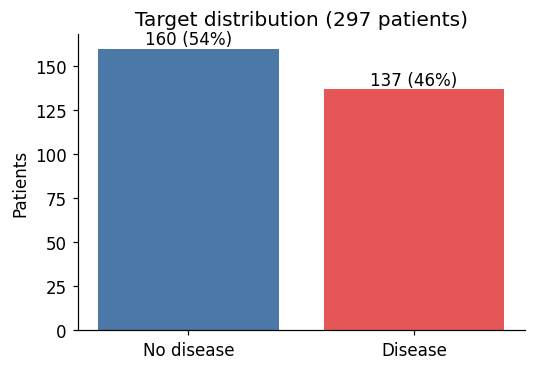

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["No disease", "Disease"], counts.values, color=["#4C78A8", "#E45756"])
ax.bar_label(bars, labels=[f"{c} ({c / len(df):.0%})" for c in counts.values])
ax.set_ylabel("Patients")
ax.set_title("Target distribution (297 patients)")
fig.tight_layout()
fig.savefig("figures/01_target_distribution.png")
plt.show()

## 2. Preprocessing

Four variables are categories stored as numbers (for example `thal` = 3, 6 or 7). A tree would treat them as ordered numbers, which makes no sense here. We **one-hot encode** them into yes/no columns with readable names, so a split reads like "thal = normal?".

The list of categories is fixed in advance (it comes from the data dictionary), so nothing is learned from the data here either. Trees do not need scaling.

In [6]:
category_names = {
    "chest_pain": {1: "typical_angina", 2: "atypical_angina", 3: "non_anginal", 4: "asymptomatic"},
    "rest_ecg": {0: "normal", 1: "st_t_abnormal", 2: "lv_hypertrophy"},
    "st_slope": {1: "up", 2: "flat", 3: "down"},
    "thal": {3: "normal", 6: "fixed_defect", 7: "reversible_defect"},
}
X = df.drop(columns="disease").copy()
for col, names in category_names.items():
    X[col] = pd.Categorical(X[col].map(names), categories=list(names.values()))
X = pd.get_dummies(X, columns=list(category_names), dtype=int)
y = df["disease"]
print(X.shape)
list(X.columns)

(297, 22)


['age',
 'sex',
 'rest_bp',
 'cholesterol',
 'high_fasting_sugar',
 'max_heart_rate',
 'exercise_angina',
 'st_depression',
 'n_vessels',
 'chest_pain_typical_angina',
 'chest_pain_atypical_angina',
 'chest_pain_non_anginal',
 'chest_pain_asymptomatic',
 'rest_ecg_normal',
 'rest_ecg_st_t_abnormal',
 'rest_ecg_lv_hypertrophy',
 'st_slope_up',
 'st_slope_flat',
 'st_slope_down',
 'thal_normal',
 'thal_fixed_defect',
 'thal_reversible_defect']

## 3. Train / test split and baseline

- **Test set (25%, 75 patients):** set aside now and used once, at the very end.
- **Training set (75%, 222 patients):** used to fit and tune the tree. We tune with **5-fold cross-validation** inside the training set, because 222 patients is too few for a separate validation set.
- Both splits are **stratified**, so they keep the same share of sick patients.

**Baseline:** always predict the most common class ("no disease"). A useful model must beat it.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"train: {len(X_train)} patients, {y_train.mean():.0%} with disease")
print(f"test:  {len(X_test)} patients, {y_test.mean():.0%} with disease")

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline test accuracy (always 'no disease'): {baseline_acc:.3f}, recall: 0.000")

train: 222 patients, 46% with disease
test:  75 patients, 47% with disease
Baseline test accuracy (always 'no disease'): 0.533, recall: 0.000


## 4. How a tree chooses a split: Gini impurity

For a group of patients where a fraction $q$ is sick, the Gini impurity is $G(q) = 2q(1-q)$. It is 0 for a pure group and 0.5 for a 50/50 mix.
A split is scored by the drop from the parent's impurity to the **size-weighted** impurity of the two children. The tree tries every variable and every cut point, and keeps the biggest drop.

Below we check this by hand for the first split the tree picks on our training set.

In [8]:
def gini(q):
    return 2 * q * (1 - q)

stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train, y_train)
feature = X_train.columns[stump.tree_.feature[0]]
threshold = stump.tree_.threshold[0]
left = X_train[feature] <= threshold

rows = []
for name, mask in [("Parent (all training)", np.ones(len(y_train), bool)),
                   (f"Left: {feature} <= {threshold:g}", left.values),
                   (f"Right: {feature} > {threshold:g}", ~left.values)]:
    n, sick = mask.sum(), y_train[mask].sum()
    rows.append({"group": name, "sick / total": f"{sick} / {n}", "q": round(sick / n, 3), "G(q)": round(gini(sick / n), 3)})
gini_table = pd.DataFrame(rows)

n_left, n_right, n = left.sum(), (~left).sum(), len(left)
weighted = n_left / n * gini_table.loc[1, "G(q)"] + n_right / n * gini_table.loc[2, "G(q)"]
print(gini_table.to_string(index=False))
print(f"\nWeighted child impurity = {n_left}/{n} x {gini_table.loc[1, 'G(q)']} + {n_right}/{n} x {gini_table.loc[2, 'G(q)']} = {weighted:.3f}")
print(f"Decrease = {gini_table.loc[0, 'G(q)']} - {weighted:.3f} = {gini_table.loc[0, 'G(q)'] - weighted:.3f}")

                               group sick / total     q  G(q)
               Parent (all training)    102 / 222 0.459 0.497
Left: chest_pain_asymptomatic <= 0.5     24 / 114 0.211 0.332
Right: chest_pain_asymptomatic > 0.5     78 / 108 0.722 0.401

Weighted child impurity = 114/222 x 0.332 + 108/222 x 0.401 = 0.366
Decrease = 0.497 - 0.366 = 0.131


## 5. Tuning: how deep should the tree grow?

A deeper tree fits the training data better but can **overfit**: it learns noise that does not carry over to new patients. We try:

- `max_depth` from 1 to 10 (how many questions in a row),
- `min_samples_leaf` in {1, 5, 10, 20} (smallest group allowed in a leaf),

and keep the pair with the best **5-fold cross-validated accuracy** on the training set. If two settings tie, the shallower one wins, because it comes first in the grid.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
param_grid = {"max_depth": list(range(1, 11)), "min_samples_leaf": [1, 5, 10, 20]}
search = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid, cv=cv,
                      scoring="accuracy", return_train_score=True)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)
best_depth = search.best_params_["max_depth"]
best_leaf = search.best_params_["min_samples_leaf"]
print(f"Best: max_depth = {best_depth}, min_samples_leaf = {best_leaf}, CV accuracy = {search.best_score_:.3f}")

cv_table = results.pivot(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score").round(3)
cv_table.index.name, cv_table.columns.name = "max_depth", "min_samples_leaf"
cv_table

Best: max_depth = 4, min_samples_leaf = 10, CV accuracy = 0.824


min_samples_leaf,1,5,10,20
max_depth,,,,
1,0.716,0.716,0.716,0.716
2,0.766,0.761,0.761,0.761
3,0.815,0.797,0.820,0.775
4,0.815,0.784,0.824,0.775
5,0.797,0.766,0.820,0.775
6,0.802,0.775,0.820,0.775
7,0.784,0.775,0.820,0.775
8,0.784,0.775,0.820,0.775
9,0.784,0.775,0.820,0.775


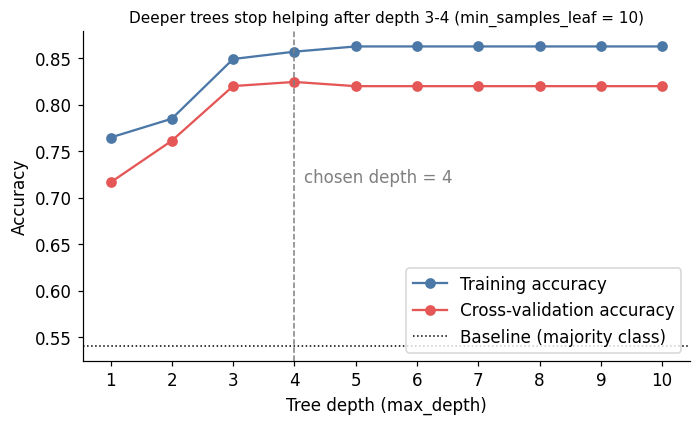

In [10]:
curve = results[results["param_min_samples_leaf"] == best_leaf].sort_values("param_max_depth")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(curve["param_max_depth"], curve["mean_train_score"], "o-", color="#4C78A8", label="Training accuracy")
ax.plot(curve["param_max_depth"], curve["mean_test_score"], "o-", color="#E45756", label="Cross-validation accuracy")
ax.axvline(best_depth, color="grey", ls="--", lw=1)
ax.annotate(f"chosen depth = {best_depth}", (best_depth, curve["mean_test_score"].min()),
            xytext=(6, 0), textcoords="offset points", color="grey")
ax.axhline(y_train.value_counts(normalize=True).max(), color="black", ls=":", lw=1, label="Baseline (majority class)")
ax.set_xlabel("Tree depth (max_depth)")
ax.set_ylabel("Accuracy")
ax.set_title(f"Deeper trees stop helping after depth 3-4 (min_samples_leaf = {best_leaf})", fontsize=10)
ax.set_xticks(range(1, 11))
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figures/02_depth_tuning.png")
plt.show()

## 6. The final tree

`GridSearchCV` refits the chosen tree on the whole training set. We freeze it now, before looking at the test set.

Final decision tree: depth 4, 12 leaves


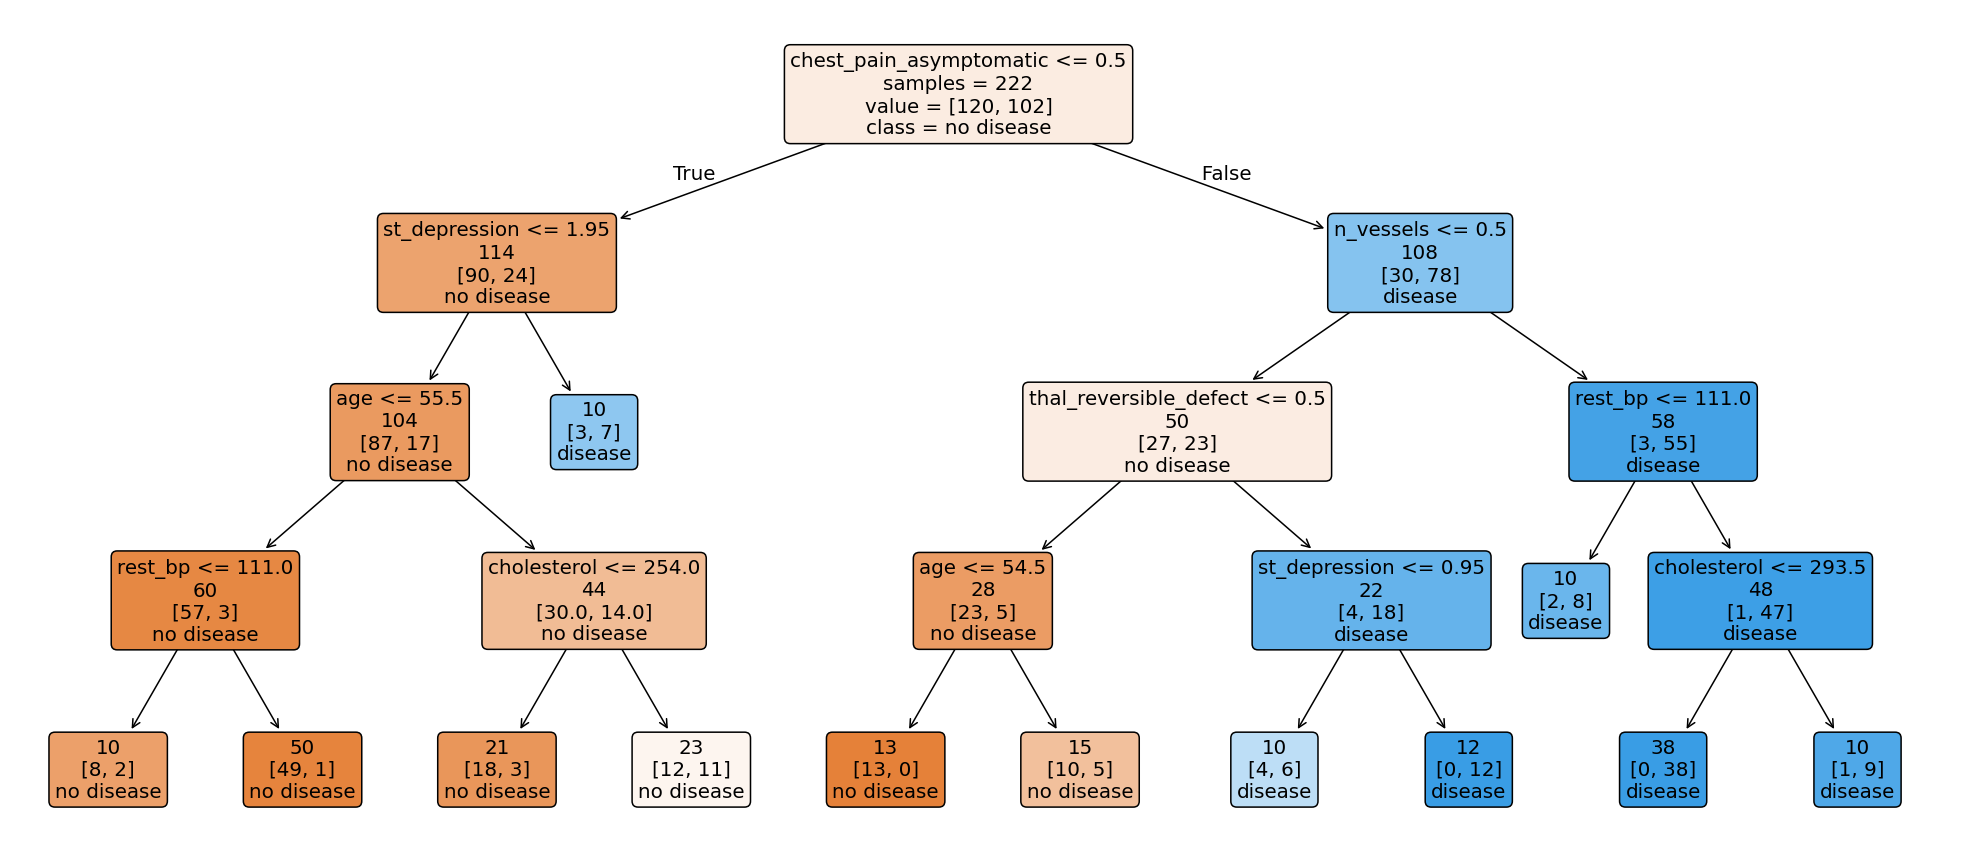

In [11]:
tree = search.best_estimator_
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, feature_names=list(X.columns), class_names=["no disease", "disease"],
          filled=True, rounded=True, impurity=False, label="root", fontsize=13, ax=ax)
print(f"Final decision tree: depth {tree.get_depth()}, {tree.get_n_leaves()} leaves")
fig.tight_layout()
fig.savefig("figures/03_final_tree.png", bbox_inches="tight", pad_inches=0.05)
plt.show()

In [12]:
print(export_text(tree, feature_names=list(X.columns), show_weights=True))

|--- chest_pain_asymptomatic <= 0.50
|   |--- st_depression <= 1.95
|   |   |--- age <= 55.50
|   |   |   |--- rest_bp <= 111.00
|   |   |   |   |--- weights: [8.00, 2.00] class: 0
|   |   |   |--- rest_bp >  111.00
|   |   |   |   |--- weights: [49.00, 1.00] class: 0
|   |   |--- age >  55.50
|   |   |   |--- cholesterol <= 254.00
|   |   |   |   |--- weights: [18.00, 3.00] class: 0
|   |   |   |--- cholesterol >  254.00
|   |   |   |   |--- weights: [12.00, 11.00] class: 0
|   |--- st_depression >  1.95
|   |   |--- weights: [3.00, 7.00] class: 1
|--- chest_pain_asymptomatic >  0.50
|   |--- n_vessels <= 0.50
|   |   |--- thal_reversible_defect <= 0.50
|   |   |   |--- age <= 54.50
|   |   |   |   |--- weights: [13.00, 0.00] class: 0
|   |   |   |--- age >  54.50
|   |   |   |   |--- weights: [10.00, 5.00] class: 0
|   |   |--- thal_reversible_defect >  0.50
|   |   |   |--- st_depression <= 0.95
|   |   |   |   |--- weights: [4.00, 6.00] class: 1
|   |   |   |--- st_depression >  0.

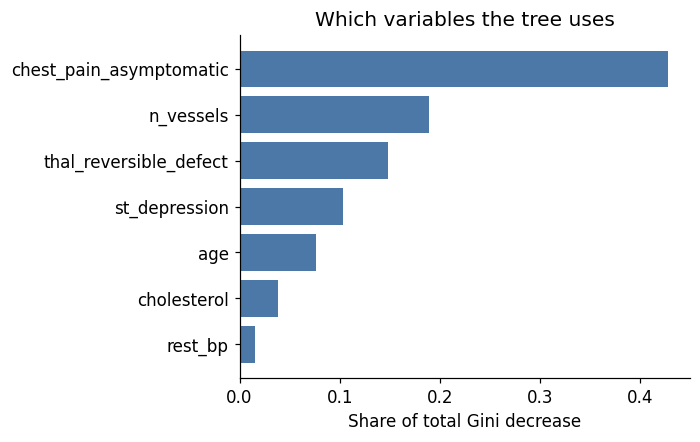

chest_pain_asymptomatic    0.428
n_vessels                  0.189
thal_reversible_defect     0.149
st_depression              0.103
age                        0.077
cholesterol                0.039
rest_bp                    0.016
dtype: float64

In [13]:
importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values()
importance = importance[importance > 0]
fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(importance) + 1))
ax.barh(importance.index, importance.values, color="#4C78A8")
ax.set_xlabel("Share of total Gini decrease")
ax.set_title("Which variables the tree uses")
fig.tight_layout()
fig.savefig("figures/04_feature_importance.png")
plt.show()
importance.sort_values(ascending=False).round(3)

## 7. Test results (used once)

In [14]:
y_pred = tree.predict(X_test)
test_table = pd.DataFrame({
    "model": ["Baseline (always 'no disease')", f"Decision tree (depth {tree.get_depth()})"],
    "test accuracy": [baseline_acc, accuracy_score(y_test, y_pred)],
    "recall (sick patients caught)": [0.0, recall_score(y_test, y_pred)],
}).round(3)
test_table

,model,test accuracy,recall (sick patients caught)
0,Baseline (always 'no disease'),0.533,0.000
1,Decision tree (depth 4),0.773,0.686


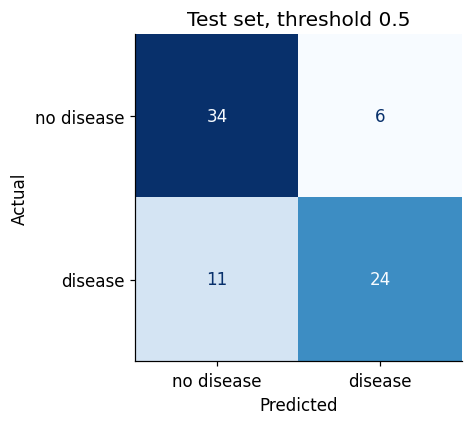

In [15]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["no disease", "disease"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Test set, threshold 0.5")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
fig.tight_layout()
fig.savefig("figures/05_confusion_matrix.png")
plt.show()

## 8. From prediction to decision: the cost of each mistake

The diagnosis in this dataset comes from **angiography**: an invasive, costly test. The real decision is: **should this patient be sent for angiography?**

Accuracy counts every mistake the same. For the doctor they are not the same. We measure costs in units of "one angiography":

| Loss $L(a, Y)$ | healthy ($Y=0$) | sick ($Y=1$) |
|---|---|---|
| do not send ($a=0$) | 0 | $c$ (missed disease) |
| send for angiography ($a=1$) | 1 | 1 |

Each leaf of the tree gives a probability $\hat p(x)$ = share of sick training patients in that leaf. The expected loss is
$\hat\rho(0 \mid x) = c\,\hat p(x)$ if we do not send, and $\hat\rho(1 \mid x) = 1$ if we send. So the Bayes rule is to **send when $\hat p(x) > 1/c$**, not when $\hat p(x) > 0.5$.

**Example:** a missed sick patient costs $c = 3$ angiographies, so we send when $\hat p(x) > 1/3$.

In [16]:
def average_cost(send, y_true, c):
    send, y_true = np.asarray(send), np.asarray(y_true)
    return np.mean(np.where(send == 1, 1, c * y_true))

def policy_rows(p, y_true, c):
    policies = {
        "Send nobody": np.zeros(len(y_true), int),
        "Send everybody": np.ones(len(y_true), int),
        "Tree, send if p > 0.5": (p > 0.5).astype(int),
        f"Tree, send if p > 1/{c} (cost rule)": (p > 1 / c).astype(int),
    }
    return pd.DataFrame([{
        "policy": name,
        "patients sent": int(send.sum()),
        "sick patients missed": int(((send == 0) & (np.asarray(y_true) == 1)).sum()),
        "average cost per patient": round(average_cost(send, y_true, c), 3),
    } for name, send in policies.items()])

p_test = tree.predict_proba(X_test)[:, 1]
print(f"Test set: {len(y_test)} patients, {y_test.sum()} sick. Missed patient cost c = 3.")
policy_table = policy_rows(p_test, y_test, c=3)
policy_table

Test set: 75 patients, 35 sick. Missed patient cost c = 3.


,policy,patients sent,sick patients missed,average cost per patient
0,Send nobody,0,35,1.400
1,Send everybody,75,0,1.000
2,"Tree, send if p > 0.5",30,11,0.840
3,"Tree, send if p > 1/3 (cost rule)",34,10,0.853


**How much does the answer depend on $c$?** We do not know the true cost of a missed patient, so we repeat the comparison for several values of $c$. The tree is frozen; only the threshold $1/c$ changes.

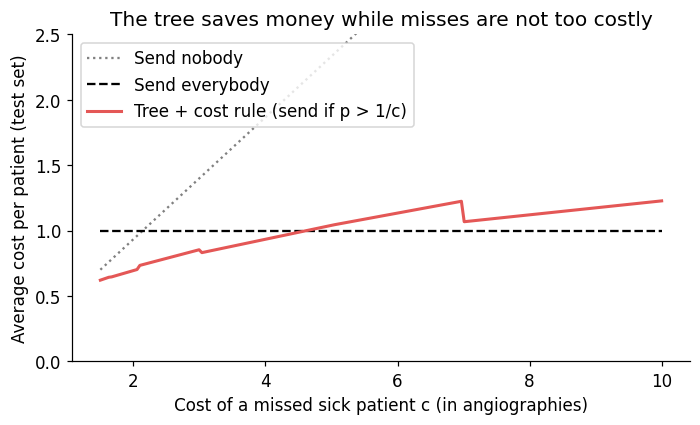

,c (cost of a miss),threshold 1/c,send nobody,send everybody,tree (cost rule)
0,2,0.50,0.933,1.0,0.693
1,3,0.33,1.400,1.0,0.853
2,4,0.25,1.867,1.0,0.933
3,5,0.20,2.333,1.0,1.040
4,10,0.10,4.667,1.0,1.227


In [17]:
sensitivity = []
for c in [2, 3, 4, 5, 10]:
    t = policy_rows(p_test, y_test, c).set_index("policy")["average cost per patient"]
    sensitivity.append({"c (cost of a miss)": c, "threshold 1/c": round(1 / c, 2),
                        "send nobody": t.iloc[0], "send everybody": t.iloc[1], "tree (cost rule)": t.iloc[3]})
sensitivity = pd.DataFrame(sensitivity)

c_grid = np.linspace(1.5, 10, 200)
tree_curve = [average_cost((p_test > 1 / c).astype(int), y_test, c) for c in c_grid]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(c_grid, c_grid * y_test.mean(), color="grey", ls=":", label="Send nobody")
ax.plot(c_grid, np.ones_like(c_grid), color="black", ls="--", label="Send everybody")
ax.plot(c_grid, tree_curve, color="#E45756", lw=2, label="Tree + cost rule (send if p > 1/c)")
ax.set_ylim(0, 2.5)
ax.set_xlabel("Cost of a missed sick patient c (in angiographies)")
ax.set_ylabel("Average cost per patient (test set)")
ax.set_title("The tree saves money while misses are not too costly")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figures/06_cost_sensitivity.png")
plt.show()
sensitivity

## 9. Summary numbers for the slides

In [18]:
tree_cost = policy_table.iloc[3]
summary = {
    "patients used": len(df),
    "share with disease": round(y.mean(), 3),
    "chosen max_depth": best_depth,
    "chosen min_samples_leaf": best_leaf,
    "number of leaves": tree.get_n_leaves(),
    "CV accuracy (training)": round(search.best_score_, 3),
    "baseline test accuracy": round(baseline_acc, 3),
    "tree test accuracy": round(accuracy_score(y_test, y_pred), 3),
    "tree test recall (0.5)": round(recall_score(y_test, y_pred), 3),
    "cost rule c=3: average cost": tree_cost["average cost per patient"],
    "cost rule c=3: patients sent": tree_cost["patients sent"],
    "cost rule c=3: sick missed": tree_cost["sick patients missed"],
}
pd.Series(summary, name="value").to_frame()

,value
patients used,297.000
share with disease,0.461
chosen max_depth,4.000
chosen min_samples_leaf,10.000
number of leaves,12.000
CV accuracy (training),0.824
baseline test accuracy,0.533
tree test accuracy,0.773
tree test recall (0.5),0.686
cost rule c=3: average cost,0.853


## 10. Limitations

- **Small data:** 297 patients from one hospital in 1988. A different random split can give a somewhat different tree and test score.
- **Costs are assumed:** we do not know the real cost $c$ of a missed patient. The sensitivity plot shows that the tree helps only while $c$ stays below about 4-5 angiographies. Above that, sending everybody is as good or better.
- **Some inputs are tests too:** `n_vessels` (fluoroscopy) and `thal` (thallium stress test) are themselves medical tests, so the tree assumes these were already done.
- **Only one test set of 75 patients:** each patient is about 1.3 accuracy points, so small differences are not meaningful.
- **Old, mostly male sample:** results may not carry over to other populations.